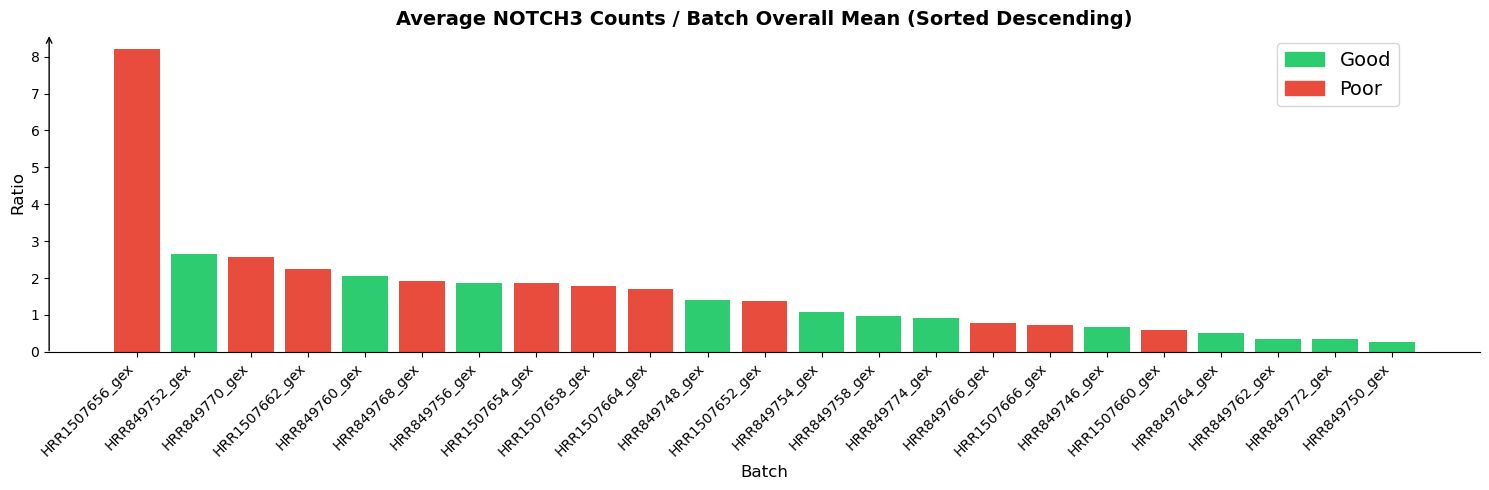

In [10]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

adata = sc.read("../h5ad/adata.h5ad")

gene_name = "NOTCH3"
batch2effect = {
    'HRR1507652_gex': "poor", "HRR1507654_gex": "poor",
    "HRR1507656_gex": "poor", "HRR1507658_gex": "poor",
    'HRR1507660_gex': "poor", 'HRR1507662_gex': "poor",
    'HRR1507664_gex': "poor", 'HRR1507666_gex': "poor",
    'HRR849746_gex': "good", 'HRR849748_gex': "good",
    'HRR849750_gex': "good", 'HRR849752_gex': "good",
    'HRR849754_gex': "good", 'HRR849756_gex': "good",
    'HRR849758_gex': "good", 'HRR849760_gex': "good",
    'HRR849762_gex': "good", 'HRR849764_gex': "good",
    'HRR849766_gex': "poor", 'HRR849768_gex': "poor",
    'HRR849770_gex': "poor", 'HRR849772_gex': "good",
    'HRR849774_gex': "good"
}

ratios, batch_names, effects = [], [], []

for batch, effect in batch2effect.items():
    adata_batch = adata[adata.obs['batch'] == batch]
    notch3_mean = adata_batch[:, gene_name].X.mean()
    overall_batch_mean = adata_batch.X.mean()
    ratios.append(notch3_mean / overall_batch_mean)
    batch_names.append(batch)
    effects.append(effect)

sorted_indices = sorted(range(len(ratios)), key=lambda i: -ratios[i])
sorted_batches = [batch_names[i] for i in sorted_indices]
sorted_ratios = [ratios[i] for i in sorted_indices]
sorted_effects = [effects[i] for i in sorted_indices]

plt.figure(figsize=(15, 5))
colors = ['#2ecc71' if e == 'good' else '#e74c3c' for e in sorted_effects]
plt.bar(sorted_batches, sorted_ratios, color=colors)

plt.title('Average NOTCH3 Counts / Batch Overall Mean (Sorted Descending)', fontsize=14, fontweight="bold")
plt.xlabel('Batch', fontsize=12)
plt.ylabel('Ratio', fontsize=12)
plt.xticks(rotation=45, ha='right')

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.annotate(
    '', xy=(0, 1), xytext=(0, -0.005),
    xycoords='axes fraction', textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.), clip_on=False
)

good_patch = mpatches.Patch(color='#2ecc71', label='Good')
poor_patch = mpatches.Patch(color='#e74c3c', label='Poor')
plt.legend(handles=[good_patch, poor_patch], loc='upper right', fontsize=14, bbox_to_anchor=(0.95, 1.0))

plt.tight_layout()
plt.show()